# Advection: CFL, dissipation and dispersion

**Source:** CompSci §5.3.4, pp. 45–48 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

For positive $u$, explicit upwind gives $c_j^{n+1}=(1-\nu)c_j^n+\nu c_{j-1}^n$, $\nu=uh/\Delta x$. For negative $u$ reverse the stencil and use $|\nu|$. The convex combination for $0\le\nu\le1$ gives an infinity-norm bound. Its amplification factor is $G=1-\nu(1-e^{-i\theta})$. Centred forward Euler gives $G=1-i\nu\sin\theta$, with modulus larger than one for most nonconstant modes. The exact factor is $e^{-i\nu\theta}$. Modulus error changes amplitude (dissipation or growth); phase error changes propagation speed (dispersion).

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


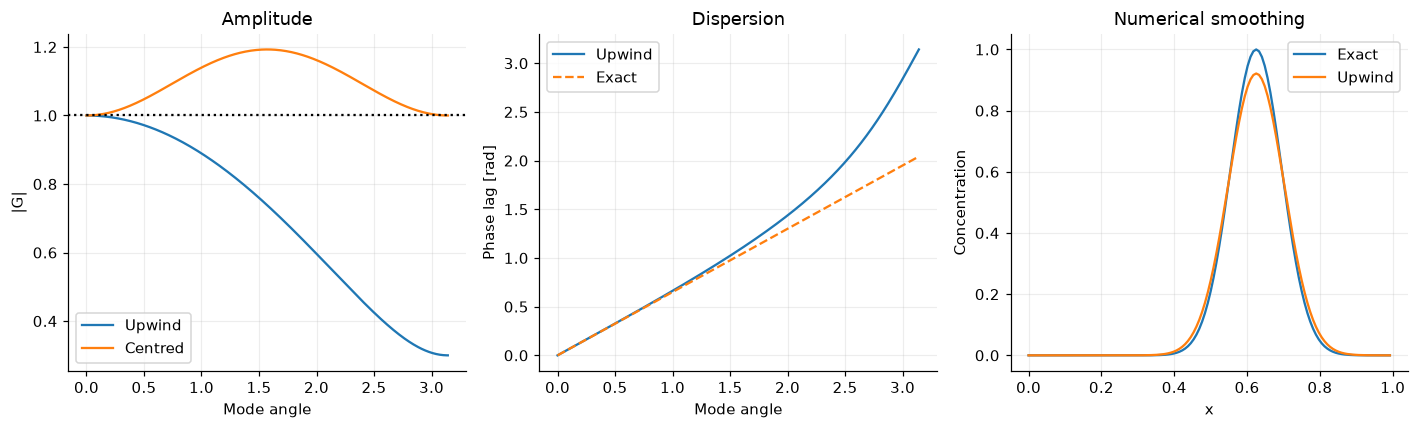

In [2]:
theta=np.linspace(0,np.pi,401); nu=.65
up=1-nu*(1-np.exp(-1j*theta)); centered=1-1j*nu*np.sin(theta)
fig,ax=plt.subplots(1,3,figsize=(13,4))
ax[0].plot(theta,abs(up),label="Upwind"); ax[0].plot(theta,abs(centered),label="Centred")
ax[0].axhline(1,color="k",ls=":"); ax[0].set(xlabel="Mode angle",ylabel="|G|",title="Amplitude"); ax[0].legend()
ax[1].plot(theta,-np.unwrap(np.angle(up)),label="Upwind")
ax[1].plot(theta,nu*theta,"--",label="Exact")
ax[1].set(xlabel="Mode angle",ylabel="Phase lag [rad]",title="Dispersion"); ax[1].legend()
n=128; x=np.arange(n)/n; steps=64
def pulse(x): return np.exp(-100*(np.mod(x-.3+.5,1)-.5)**2)
y=pulse(x)
for _ in range(steps): y=(1-nu)*y+nu*np.roll(y,1)
ax[2].plot(x,pulse(x-nu*steps/n),label="Exact"); ax[2].plot(x,y,label="Upwind")
ax[2].set(xlabel="x",ylabel="Concentration",title="Numerical smoothing"); ax[2].legend()
show(fig,"07-advection")
assert max(abs(up))<=1+1e-12 and max(abs(centered))>1.1
assert np.isclose(y.sum(),pulse(x).sum())
assert y.max()<pulse(x).max()

## Worked exercise

**What is special about $\nu=1$?** The method shifts the grid values exactly one cell per step, so amplitude and phase are both exact for resolved grid modes. This applies to constant velocity on this grid.